In [4]:
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np
import seaborn as sns

In [5]:
df = pd.read_csv(r"C:\Users\Marcelo\Documents\proyrepasodipl\LearningProject\data\raw\bank-full.csv", sep=";")

In [6]:
df_limpio =df.copy()

In [7]:
df_limpio['aceptacion'] = df_limpio['y'].replace(['no','yes'],['0','1'])

In [8]:
df_limpio['aceptacion']=df_limpio['aceptacion'].astype(int)

In [9]:
df_limpio

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y,aceptacion
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes,1
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes,1
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes,1
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no,0


In [10]:
serie=df_limpio.groupby("job")["aceptacion"].mean().sort_values(ascending=True)*100

<Axes: ylabel='job'>

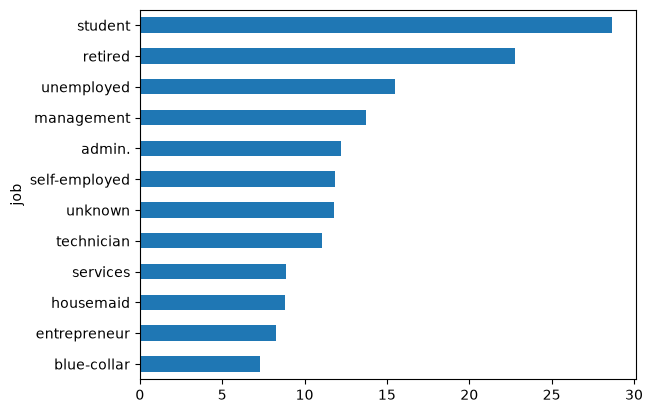

In [11]:
serie.plot(kind='barh')

In [12]:
glbl = df_limpio["aceptacion"].mean() * 100 

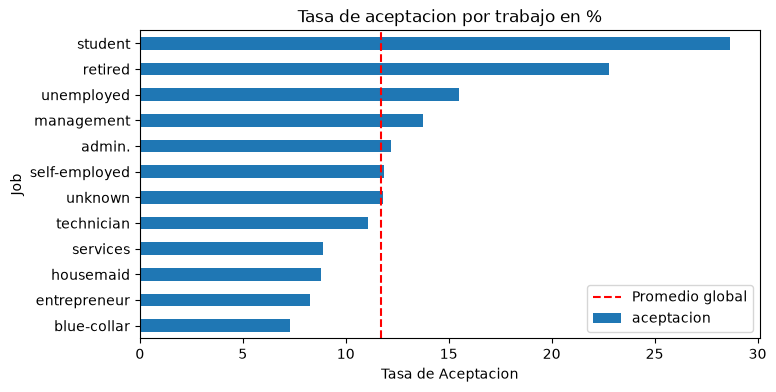

In [13]:
fig, ax1 = plt.subplots(figsize=(8, 4))
serie.plot(kind="barh", ax=ax1, rot=0)
ax1.axvline(x=glbl, color="red", linestyle="--", label="Promedio global")
ax1.legend()
ax1.set_ylabel("Job")
ax1.set_xlabel("Tasa de Aceptacion")
ax1.set_title("Tasa de aceptacion por trabajo en %")
plt.show()

In [14]:
df_limpio.groupby("job")["aceptacion"].agg(["mean", "size"])

,mean,size
job,,
admin.,0.122027,5171
blue-collar,0.072750,9732
entrepreneur,0.082717,1487
housemaid,0.087903,1240
management,0.137556,9458
retired,0.227915,2264
self-employed,0.118429,1579
services,0.088830,4154
student,0.286780,938


In [15]:
df_limpio_filtrado1 = df_limpio[df_limpio['job'].isin(["student","retired"])]

In [16]:
df_limpio_filtrado1

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y,aceptacion
8,58,retired,married,primary,no,121,yes,no,unknown,5,may,50,1,-1,0,unknown,no,0
15,51,retired,married,primary,no,229,yes,no,unknown,5,may,353,1,-1,0,unknown,no,0
18,60,retired,married,primary,no,60,yes,no,unknown,5,may,219,1,-1,0,unknown,no,0
24,40,retired,married,primary,no,0,yes,yes,unknown,5,may,181,1,-1,0,unknown,no,0
43,54,retired,married,secondary,no,529,yes,no,unknown,5,may,1492,1,-1,0,unknown,no,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45196,25,student,single,secondary,no,358,no,no,cellular,16,nov,330,1,-1,0,unknown,yes,1
45203,23,student,single,tertiary,no,113,no,no,cellular,17,nov,266,1,-1,0,unknown,yes,1
45204,73,retired,married,secondary,no,2850,no,no,cellular,17,nov,300,1,40,8,failure,yes,1
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes,1


In [17]:
df_limpio["rango"] = pd.cut(df_limpio["age"], bins=[ 0,30, 50, 100], labels=["<30", "30-50", ">50"])


In [18]:
res = df_limpio.groupby(["rango", "job"])["aceptacion"].agg(["mean", "size"])


In [19]:
res

mean  size
rango job                          
<30   admin.         0.148033   966
      blue-collar    0.111266  1438
      entrepreneur   0.088889   135
      housemaid      0.119403    67
      management     0.194514  1203
      retired        0.000000     4
      self-employed  0.209677   248
      services       0.111922   822
      student        0.305592   769
      technician     0.146194  1156
      unemployed     0.177340   203
      unknown        0.210526    19
30-50 admin.         0.111176  3427
      blue-collar    0.065941  6794
      entrepreneur   0.079767  1028
      housemaid      0.070809   692
      management     0.126890  6549
      retired        0.040541   148
      self-employed  0.099029  1030
      services       0.083934  2776
      student        0.201183   169
      technician     0.099175  5334
      unemployed     0.145455   825
      unknown        0.103896   154
>50   admin.         0.137532   778
      blue-collar    0.066667  1500
      entrepreneur   0.089506   324
      housemaid      0.108108   481
      management     0.138335  1706
      retired        0.241477  2112
      self-employed  0.109635   301
      services       0.079137   556
      technician     0.128275  1107
      unemployed     0.167273   275
      unknown        0.121739   115

In [20]:
res["mean"].unstack() * 100

job,admin.,blue-collar,entrepreneur,housemaid,management,retired,self-employed,services,student,technician,unemployed,unknown
rango,,,,,,,,,,,,
<30,14.803313,11.126565,8.888889,11.940299,19.451372,0.000000,20.967742,11.192214,30.559168,14.619377,17.733990,21.052632
30-50,11.117596,6.594054,7.976654,7.080925,12.688960,4.054054,9.902913,8.393372,20.118343,9.917510,14.545455,10.389610
>50,13.753213,6.666667,8.950617,10.810811,13.833529,24.147727,10.963455,7.913669,NaN,12.827462,16.727273,12.173913


In [21]:
df_limpio["grupo"] = df_limpio["job"].where(df_limpio["job"].isin(["student", "retired"]), "otros")


In [22]:
res1 = df_limpio.groupby(["rango", "grupo"])["aceptacion"].agg(["mean", "size"])


In [23]:
res1

mean   size
rango grupo                   
<30   otros    0.145437   6257
      retired  0.000000      4
      student  0.305592    769
30-50 otros    0.097557  28609
      retired  0.040541    148
      student  0.201183    169
>50   otros    0.112418   7143
      retired  0.241477   2112

Comparando dentro de cada rango de edad, student en menores de 30 acepta 30,5% frente a 14,5% de otros (769 llamadas), y retired en mayores de 50 acepta 24,1% frente a 11,2% (2.112 llamadas). El trabajo influye en la aceptación más allá de la edad. En 30-50, student también supera a otros (20% frente a 9,7%), pero con solo 169 llamadas, así que se toma con cautela. Es una asociación, no una causa.

### Decisión: `unknown` en `job`

- 288 filas (~0,6% del total). Tasa de aceptación global ≈ promedio general (~12%).
- Por tramo de edad la tasa varía (19 <30: ~21%; 30-50: 10,3%; >50: 12,1%), pero con muestras muy pequeñas por tramo, por lo que la diferencia no es concluyente.
- **Decisión:** mantener `unknown` como categoría propia. Eliminarlas aporta poco (volumen mínimo) y no hay evidencia de que sean ruido; el modelo puede usarlas si aportan señal.
- Pendiente (otro proyecto): revisar si `unknown` en `job` se concentra en algún canal o campaña.

In [24]:
df_limpio.groupby("education")["aceptacion"].agg(["mean", "size"])

,mean,size
education,,
primary,0.086265,6851
secondary,0.105594,23202
tertiary,0.150064,13301
unknown,0.135703,1857


In [25]:
df_limpio["aceptacion"].mean()

np.float64(0.11698480458295547)

### Decisión: `unknown` en `education`

- 1.857 filas (~4,1% del total). Tasa de aceptación: 13,6% (global: 11,7%).
- La educación tiene gradiente claro: primary 8,6% → secondary 10,6% → tertiary 15,0%. `unknown` queda entre secondary y tertiary, y se diferencia de secondary (~3 pts con n grandes), por lo que no se comporta como la categoría más frecuente.
- **Decisión:** mantener `unknown` como categoría propia. Imputar con la moda (`secondary`) distorsionaría su tasa real, y eliminarlas descartaría ~4% de datos sin evidencia de que sean ruido.
- Pendiente (otro proyecto): revisar si `unknown` en `education` se concentra en ciertos `job` o campañas.

In [26]:
#creando columna contactado antes

df_limpio['contactado_antes'] = [1 if x > 0 else 0 for x in df_limpio["pdays"]]

In [27]:
df_limpio['contactado_antes'].value_counts()

contactado_antes
0    36954
1     8257
Name: count, dtype: int64

In [28]:
df_limpio.groupby("contactado_antes")["aceptacion"].agg(["mean", "size"])

,mean,size
contactado_antes,,
0,0.091573,36954
1,0.230713,8257


### Feature: `contactado_antes`

- Se construye a partir de `pdays` (`pdays != -1`), porque `pdays=-1` significa "nunca contactado" sin ambigüedad (`poutcome=unknown` mezcla 36.954 no contactados con 5 contactados sin resultado registrado).
- Validación: 0 → 36.954 filas, 1 → 8.257 filas.
- Tasa de aceptación: 9,2% (no contactados) vs 23,1% (contactados antes), unas 2,5 veces más.
- El flag aporta señal fuerte. Es una asociación: el banco eligió a quién llamar, por lo que los grupos pueden diferir en otros aspectos.
- Pendiente (otro proyecto): revisar si la diferencia se mantiene al controlar por `poutcome=success`.

In [29]:
df_limpio["pdays"] = df_limpio["pdays"].replace(-1,np.nan)

In [30]:
df_limpio["pdays"].isna().sum()

np.int64(36954)

In [31]:
df_limpio["pdays"].mean()

np.float64(224.57769165556496)

### Decisión: `pdays` con `-1`

- `pdays=-1` es un código para "nunca contactado", no un número real, y distorsiona cualquier promedio (40 días con el -1 frente a ~225 sin él).
- **Decisión:** reemplazar `-1` por `NaN` y conservar la columna. Aporta información útil (hace cuánto fue el último contacto) para los 8.257 clientes contactados antes. La columna `contactado_antes` ya guarda si hubo contacto.
- Validación: 36.954 `NaN` y promedio de 224,6 días.
- Pendiente (fase de modelado): ~82% de la columna queda en `NaN`. Decidir si se imputa con un valor apoyándose en el flag, o si se usa un modelo que tolere `NaN` (p. ej. `HistGradientBoosting`).

In [32]:
serie=df_limpio.groupby("job")["aceptacion"].mean().sort_values(ascending=True)*100
tabla = serie.reset_index()   # columnas: "region" y "convierte"


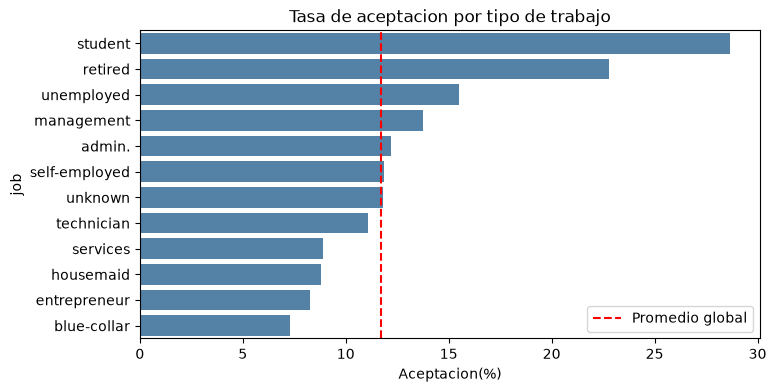

In [33]:
df_ej = tabla.sort_values("aceptacion", ascending=False)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=df_ej, x="aceptacion", y="job", color="steelblue", ax=ax)
ax.axvline(glbl, color="red", linestyle="--", label="Promedio global")
ax.set_xlabel("Aceptacion(%)")
ax.set_title("Tasa de aceptacion por tipo de trabajo")
ax.legend()
plt.show()

### Resumen: tratamiento de los `unknown`

Todos los `unknown` se mantienen, pero por motivos distintos:

| Variable | Filas | Tasa de aceptación | Por qué se mantiene |
|---|---|---|---|
| `job` | 288 (~0,6%) | ~12% (≈ global) | No hay evidencia de que sea distinto, y eliminarlo aporta poco. No vale la pena tocarlo. |
| `education` | 1.857 (~4,1%) | 13,6% | Se comporta distinto (entre secondary y tertiary). Imputar con la moda distorsionaría su tasa real. |
| `contact` | 28,8% | Menor que las demás categorías, incluso dentro del mismo mes | Tiene una señal propia que no hay que perder. Causa por determinar. |
| `pdays` / `poutcome` | 81,7% | 9,2% (no contactados) | Es "no hubo campaña anterior", no un dato faltante. `-1` pasó a `NaN` y se creó `contactado_antes`. |

- Pendiente (fase de modelado): codificar las categorías (p. ej. one-hot) y decidir si `poutcome` se conserva, dado que `contactado_antes` cubre buena parte de su información.

## SABADO: CREACION DE VARIABLE

In [34]:
df_limpio[df_limpio['aceptacion']== 1]

,age,job,marital,education,default,balance,housing,loan,contact,day,...,duration,campaign,pdays,previous,poutcome,y,aceptacion,rango,grupo,contactado_antes
83,59,admin.,married,secondary,no,2343,yes,no,unknown,5,...,1042,1,NaN,0,unknown,yes,1,>50,otros,0
86,56,admin.,married,secondary,no,45,no,no,unknown,5,...,1467,1,NaN,0,unknown,yes,1,>50,otros,0
87,41,technician,married,secondary,no,1270,yes,no,unknown,5,...,1389,1,NaN,0,unknown,yes,1,30-50,otros,0
129,55,services,married,secondary,no,2476,yes,no,unknown,5,...,579,1,NaN,0,unknown,yes,1,>50,otros,0
168,54,admin.,married,tertiary,no,184,no,no,unknown,5,...,673,2,NaN,0,unknown,yes,1,>50,otros,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45204,73,retired,married,secondary,no,2850,no,no,cellular,17,...,300,1,40.0,8,failure,yes,1,>50,retired,1
45205,25,technician,single,secondary,no,505,no,yes,cellular,17,...,386,2,NaN,0,unknown,yes,1,<30,otros,0
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,...,977,3,NaN,0,unknown,yes,1,>50,otros,0
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,...,456,2,NaN,0,unknown,yes,1,>50,retired,0


In [35]:
df_limpio.groupby(["housing", "loan"])["aceptacion"].agg(["mean", "size"])

mean   size
housing loan                 
no      no    0.182225  17204
        yes   0.076121   2877
yes     no    0.080432  20763
        yes   0.060682   4367

In [36]:
df_limpio["n_creditos"] = (df_limpio["housing"] == "yes").astype(int) + (df_limpio["loan"] == "yes").astype(int)

In [37]:
df_limpio["n_creditos"].value_counts()

n_creditos
1    23640
0    17204
2     4367
Name: count, dtype: int64

In [38]:
df_limpio.groupby("n_creditos")["aceptacion"].agg(["mean", "size"])

,mean,size
n_creditos,,
0,0.182225,17204
1,0.079907,23640
2,0.060682,4367


### Feature: `n_creditos`

- Se construye sumando `housing == "yes"` y `loan == "yes"` (0, 1 o 2 préstamos).
- Validación: 0 → 17.204, 1 → 23.640, 2 → 4.367 filas.
- Tasa de aceptación: 18,2% (0) → 8,0% (1) → 6,1% (2). El salto fuerte está entre 0 y 1; entre 1 y 2 hay una caída menor pero con muestras grandes.
- Se mantiene la variable de conteo (no binaria) porque conserva el escalón entre 1 y 2.
- Con un solo préstamo, "solo housing" (8,0%) y "solo loan" (7,6%) rinden casi igual, así que se pierde poca información al no distinguirlos.
- **Decisión:** eliminar `housing` y `loan` originales en el preprocesamiento para evitar redundancia (afecta sobre todo a modelos lineales).
- Es una asociación, no una causa: quienes no tienen préstamos pueden diferir en otras características.

In [39]:
df_limpio["balance"].describe()


count     45211.000000
mean       1362.272058
std        3044.765829
min       -8019.000000
25%          72.000000
50%         448.000000
75%        1428.000000
max      102127.000000
Name: balance, dtype: float64

In [40]:
(df_limpio["balance"] < 0).mean()


np.float64(0.08329831235761209)

In [41]:
df_limpio.groupby(df_limpio["balance"] < 0)["aceptacion"].agg(["mean", "size"])

,mean,size
balance,,
False,0.122548,41445
True,0.055762,3766


In [42]:
df_limpio.groupby([df_limpio["balance"] < 0, "n_creditos"])["aceptacion"].agg(["mean", "size"])

mean   size
balance n_creditos                 
False   0           0.187049  16632
        1           0.082453  21200
        2           0.060891   3613
True    0           0.041958    572
        1           0.057787   2440
        2           0.059682    754

In [43]:
df_limpio["en_sobregiro"] = [1 if x < 0 else 0 for x in df_limpio["balance"]]

In [44]:
df_limpio["en_sobregiro"].value_counts()

en_sobregiro
0    41445
1     3766
Name: count, dtype: int64

### Feature: `en_sobregiro`

- Marca 1 si `balance < 0` (cuenta en descubierto). ~8,3% de los clientes (3.766 de 45.211).
- Tasa de aceptación: 5,6% con sobregiro frente a 12,3% sin él.
- Se cruzó con `n_creditos` para descartar que fuera un reflejo de los préstamos. El efecto se mantiene, pero no es uniforme: sin préstamos, 18,7% frente a 4,2% (n=572); con uno, 8,2% frente a 5,8%; con dos, 6,1% frente a 6,0% (sin diferencia).
- Entre los sobregirados la tasa es baja y casi plana (4,2% a 6,0%) sin importar los préstamos. Es una interacción entre `en_sobregiro` y `n_creditos`.
- **Decisión:** crear `en_sobregiro` como variable aparte, ya que aporta información que `n_creditos` no tiene.
- Pendiente (otro proyecto): analizar si la tasa depende del monto sobregirado. `balance` tiene una distribución muy sesgada (mediana 448, máximo 102.127), así que decidir en modelado si se usa crudo, en tramos o transformado.
- Pendiente (modelado): para modelos lineales, probar un término de interacción `en_sobregiro × n_creditos`.

In [45]:
df_limpio.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,...,pdays,previous,poutcome,y,aceptacion,rango,grupo,contactado_antes,n_creditos,en_sobregiro
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,...,NaN,0,unknown,no,0,>50,otros,0,1,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,...,NaN,0,unknown,no,0,30-50,otros,0,1,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,...,NaN,0,unknown,no,0,30-50,otros,0,2,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,...,NaN,0,unknown,no,0,30-50,otros,0,1,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,...,NaN,0,unknown,no,0,30-50,otros,0,0,0


In [49]:
ncreditos=df_limpio.groupby("n_creditos")["aceptacion"].mean().sort_values(ascending=True)*100
tabla_creditos = ncreditos.reset_index()   # columnas: "region" y "convierte"

In [50]:
tabla_creditos

,n_creditos,aceptacion
0,2,6.068239
1,1,7.990694
2,0,18.222506


In [51]:
df_tcreditos = tabla_creditos.sort_values("aceptacion", ascending=False)

df_tcreditos

,n_creditos,aceptacion
2,0,18.222506
1,1,7.990694
0,2,6.068239


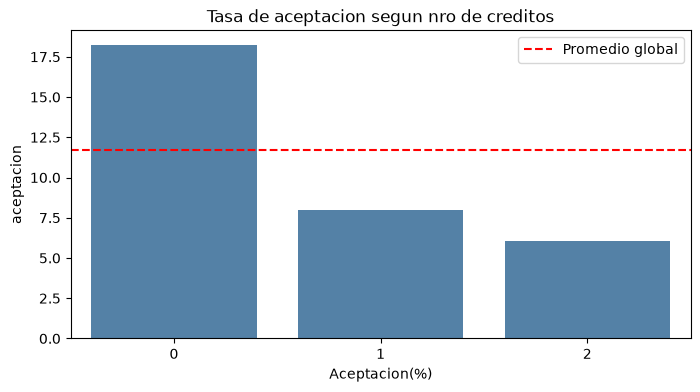

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=df_tcreditos, x="n_creditos", y="aceptacion", color="steelblue", ax=ax)
ax.axhline(glbl, color="red", linestyle="--", label="Promedio global")
ax.set_xlabel("Nro de prestamos")
ax.set_xlabel("Aceptacion(%)")
ax.set_title("Tasa de aceptacion segun nro de creditos")
ax.legend()
plt.show()

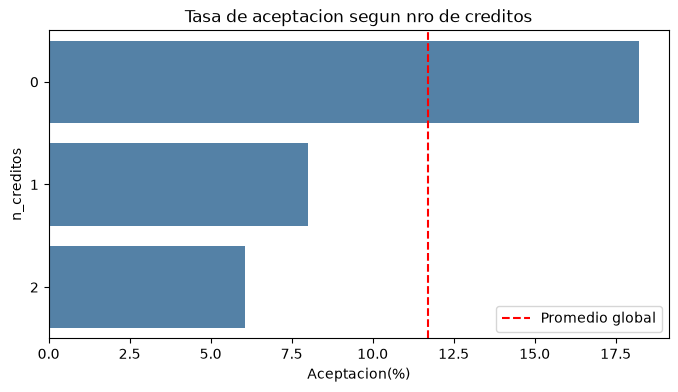

In [64]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=df_tcreditos, y="n_creditos", x="aceptacion", color="steelblue", ax=ax, orient='h')
ax.axvline(glbl, color="red", linestyle="--", label="Promedio global")
ax.set_xlabel("Nro de prestamos")
ax.set_xlabel("Aceptacion(%)")
ax.set_title("Tasa de aceptacion segun nro de creditos")
ax.legend()
plt.show()

In [58]:
df_limpio['n_creditos'].value_counts()

n_creditos
1    23640
0    17204
2     4367
Name: count, dtype: int64

In [61]:
df_limpio.groupby("n_creditos")["aceptacion"].agg(["mean","size"])


,mean,size
n_creditos,,
0,0.182225,17204
1,0.079907,23640
2,0.060682,4367


In [69]:
df2 = pd.read_csv(r"C:\Users\Marcelo\Documents\proyrepasodipl\LearningProject\data\processed\bank-full_cleaned.csv", sep=",")

In [70]:
df2.shape

(45211, 17)

In [71]:
df2['pdays'].isna().sum()

np.int64(36954)

In [72]:
df2['aceptacion'].dtype

dtype('int64')